In [1]:
import sys
import os
import numpy as np
import pandas as pd

from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_worm import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
dims = 3
dims_preca = 5

read_ids = list(range(0, 33+1))
read_ids = [0,   # minrevs
			1,   # minswitch
			7,   # maxswitch
			11,  # median
			12,  # maxrevs
			17,  # mean
			19,  # paper
			21]  # clean
# read_ids = [19]
plot_id = 19

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'exported_data_gcamp')
(file_ids, filenames,
 traces,
 continuous_behaviors,
 discrete_states, eigenworms,
 kymographs) = read_utils.get_data(path, read_ids)

# clear nan values
for i in range(len(file_ids)):
	mask = eigenworms[i].notna().all(axis=1)

	traces[i] = traces[i][mask]
	#continuous_behaviors[i] = continuous_behaviors[i][mask]
	eigenworms[i] = eigenworms[i][mask]
	discrete_states[i] = discrete_states[i][mask]

	#kymographs[i] = kymographs[i][mask]
	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
selection_n = ['VB02', 'DB01', 'DD01', 'AVBR', 'AVBL',	# paper
			   'RMDDR', 'SMDDR', 'SMDDL',				# C
			   'AVAR', 'AVAL',							# M
			   'ALA', 'AWBR']							# O
selection_bhl = ['REV', 'VENTRAL_TURN', 'DORSAL_TURN', 'PAUSE']

plot_idx = file_ids.index(plot_id)

selection_n = [label for label in selection_n if label in traces[plot_idx].columns]
# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [6]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
																	[ds[selection_bhl] for ds in discrete_states],
																	n_cv=dims, n_pc=dims_preca)

In [7]:
# for file_id in range(len(file_ids)):
# 	corrs = [
# 		np.corrcoef(modes_manifold[file_ids.index(file_id)].values[:, i], modes_manifold_b[file_ids.index(file_id)].values[:, i])[0, 1] for i in range(modes_manifold[file_ids.index(file_id)].values.shape[1])
# 	]
# 	print(f'{filenames[file_ids.index(file_id)]}')
# 	for i, corr in enumerate(corrs):
# 		print(f'\tCV {i}: {corr:.2f}')

In [8]:
save = False

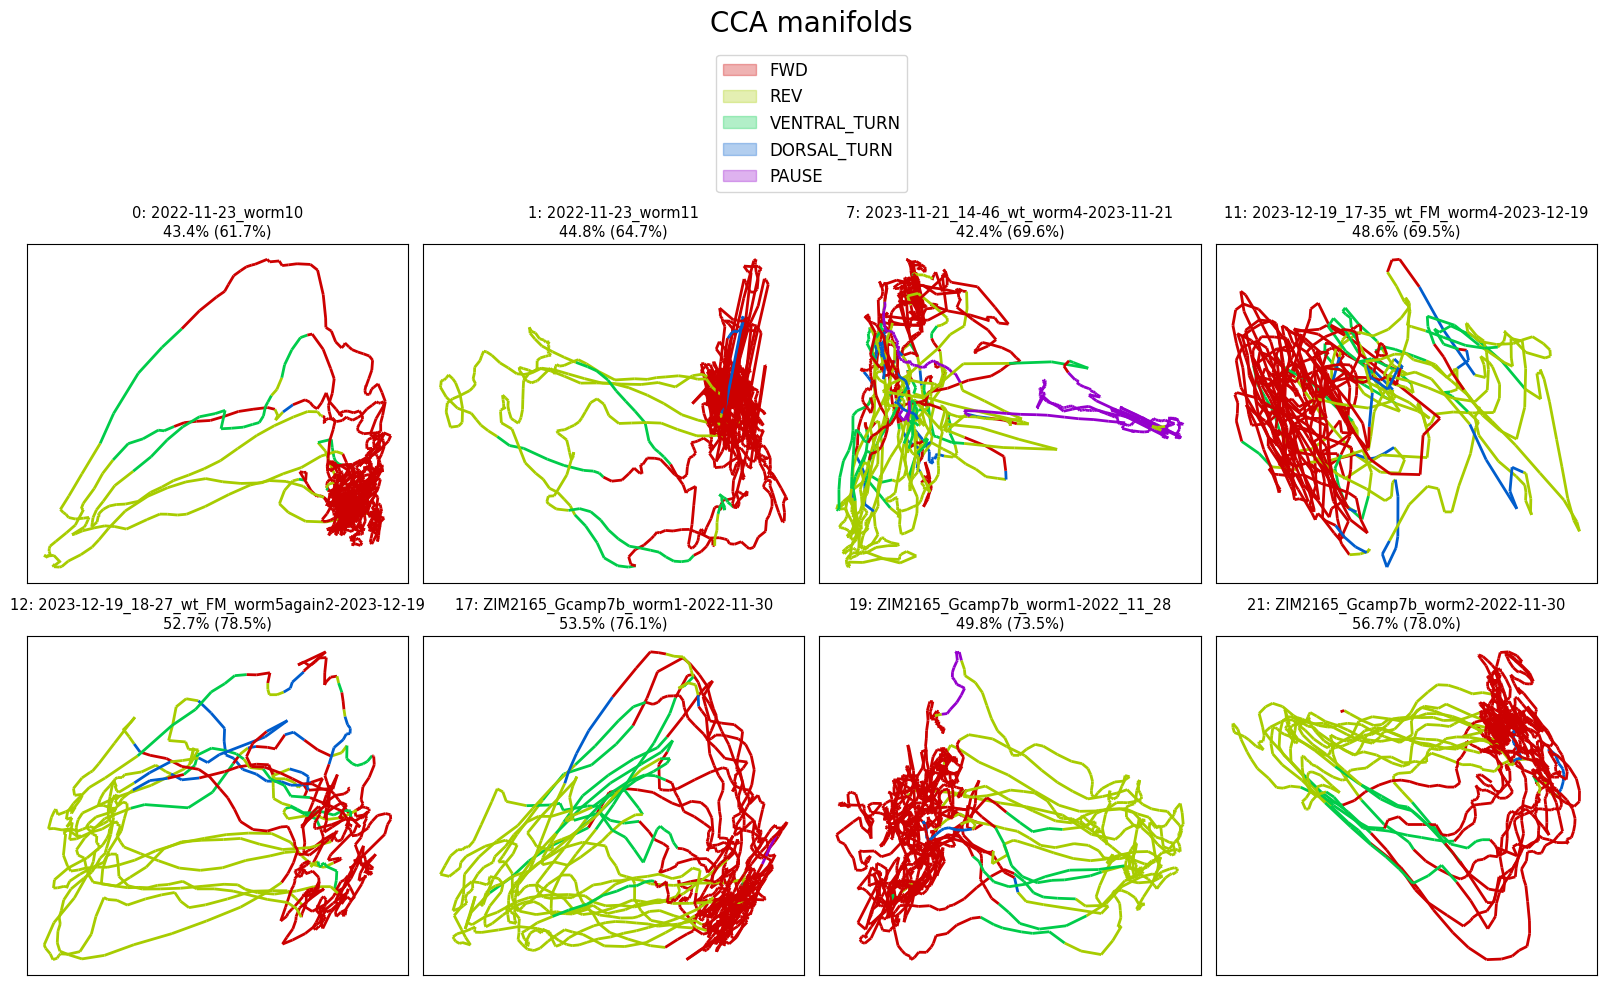

49.0% (35.7%)


In [9]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold,
						  [ds[['FWD'] + selection_bhl] for ds in discrete_states],
						  [vx[:2] for vx in vars_expl_mans], [vx[:2] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
						  title='CCA manifolds',
						  save_path=f'../../out/plots/manifolds/{dims}-dim-CCA' if save else None)

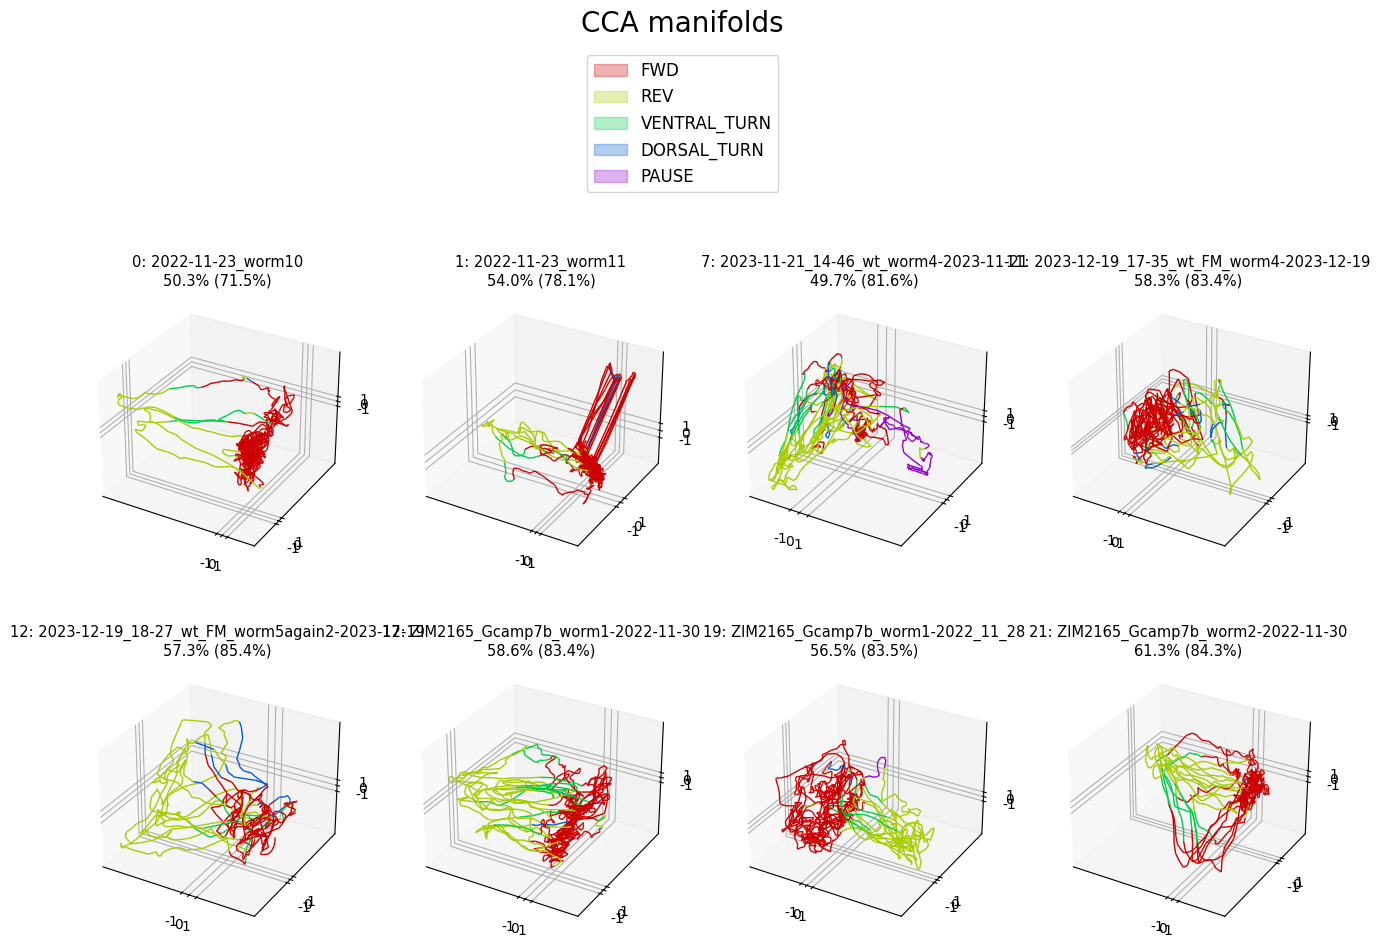

55.8% (27.1%)


In [10]:
plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
							 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
							 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
							 title='CCA manifolds',
							 save_path=f'../../out/plots/manifolds/{dims}-dim-CCA_3d' if save else None)

In [ ]:
# plot_utils.plot_manifolds_3d_sep([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 								 modes_manifold, [ds[['FWD'] + selection_bhl] for ds in discrete_states],
# 								 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
# 								 titles=['CCA manifolds'] * len(file_ids), animate=True,
# 								 save_path=f'../../out/plots/manifolds/{dims}-dim-CCA_3d' if save else None)